# WP12 — Yalnız kimlik kontrolünün düzeltilmesi
API digest ve yerel dosya hash farklı rollerdir. Yeni v2.1 ayrı dosyada; v2 ve eski iki deneme korunur. Model/API/inference çalıştırılmaz.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/gemma1b_identity_fix_v1'
c=json.loads((ROOT/'configs/WP12_GEMMA1B_IDENTITY_FIX_v2_1.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'Rol':'API/source model digest','SHA':c['expected_API_model_digest']},{'Rol':'Yerel wrapper dosya SHA','SHA':c['local_wrapper_manifest_file_sha256']},{'Rol':'Kaynak manifest dosya SHA','SHA':c['source_manifest_file_sha256']}]))
display(pd.DataFrame([json.loads((Q/'identity_only_invariants.json').read_text(encoding='utf-8'))]).T)

,Rol,SHA
0,API/source model digest,sha256:97558784bdc9175075a72655bf360b15da17df6...
1,Yerel wrapper dosya SHA,sha256:313f48e331f7326ce703657512ab64022d8813b...
2,Kaynak manifest dosya SHA,sha256:97558784bdc9175075a72655bf360b15da17df6...


,0
payload_source_identical,True
native_memory_and_GPU_functions_identical,True
admission_and_commit_and_stability_identical,True
immediate_gates_and_all_inference_control_identical,True
timeout_line_identical,True


**Yorum:**API için9755… ile yerel wrapper313f… artık ayrı kontrol edilir. Kaynak manifestin hash'i ve katman bağlantıları aynı model soyunu doğrular. Eşik/timeout veya payload değiştirilmedi.

,status,test
0,PASS,real_cache_correct_API_source_digest_passes
1,PASS,bare_API_digest_passes
2,PASS,wrapper_hash_is_rejected_as_API_identity
3,PASS,unrelated_API_digest_rejected
4,PASS,metadata_only_copy_validates_without_weight_load
5,PASS,changed_wrapper_bytes_rejected_separately
6,PASS,changed_source_manifest_bytes_rejected
7,PASS,actual_failed_run_API_identity_now_validates_2...
8,PASS,actual_failed_run_API_identity_now_validates_2...


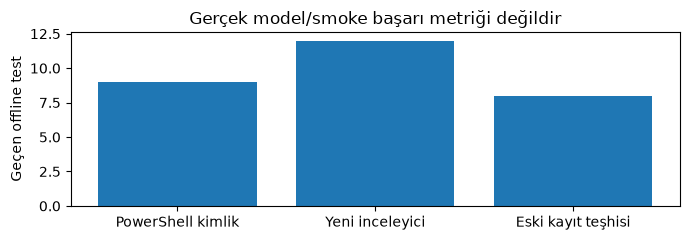

In [2]:
r=json.loads((Q/'PowerShell_identity_regressions.json').read_text(encoding='utf-8'))
display(pd.DataFrame(r['results']))
fig,ax=plt.subplots(figsize=(7,2.5));ax.bar(['PowerShell kimlik','Yeni inceleyici','Eski kayıt teşhisi'],[9,12,8]);ax.set_ylabel('Geçen offline test');ax.set_title('Gerçek model/smoke başarı metriği değildir');fig.tight_layout();F=ROOT/'reports/figures/WP12/gemma1b_identity_fix_v1';F.mkdir(parents=True,exist_ok=True);fig.savefig(F/'regression_checks.png',dpi=150);plt.show()

**Yorum:**Kimlik fonksiyonu varsayılan PowerShell motorunda yalnız yerel metadata ve geçmiş API dosyalarıyla sınandı. Windows PowerShell5.1 dosya çalıştırması yetkilendirme engeline takıldı; bu motor için runtime başarısı iddia edilmez. Smoke runner çalıştırılmadı. Yanlış API hash'i ve bozuk dosya ayrı reddediliyor.

In [3]:
display(pd.DataFrame([json.loads((Q/'runner_sha256.json').read_text(encoding='utf-8'))]).T)
print((Q/'PowerShell_syntax_check.txt').read_text(encoding='utf-8'))
for name in ['test_wp12_gemma_v2_1_smoke_review.py.log','test_wp12_gemma_failure_diagnosis.py.log']:
 print(name);print((Q/name).read_text(encoding='utf-8'))

ParseErrors=0; identity helper and v2.1 runner

test_wp12_gemma_v2_1_smoke_review.py.log
test_appcontainer_inference_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_appcontainer_inference_rejected) ... ok
test_below_three_GiB_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_below_three_GiB_rejected) ... ok
test_changed_model_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_changed_model_rejected) ... ok
test_changed_seed_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_changed_seed_rejected) ... ok
test_changed_threshold_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_changed_threshold_rejected) ... ok
test_consistent_technical_fixture_does_not_auto_release (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_consistent_technical_fixture_does_not_auto_release) ... ok
test_duplicate_echo_keys_rejected (test_wp12_gemma_v2_1_smoke_review.ExternalReviewTests.test_duplicate_echo_keys

,0
runner,scripts/WP12_Gemma1B_UserPowerShellSmoke_v2_1.ps1
sha256,86d6945fe00ae5b2d4b521cf85645f0b3bb70546f9fee9...
identity_helper,scripts/WP12_GemmaIdentity_v1.ps1
helper_sha256,27fb36d02fb9c6017450fdb8b9a54e9b3819d46465cdfd...
old_v2_runner_sha256,653c36402658f28950051be3279661a9c9cc177206f0af...
old_v2_unchanged,True
PowerShell_syntax_errors,0
identity_tests_executed_in,native PowerShell; version in PowerShell_nativ...
PowerShell_5_1_test_file_execution,blocked by AuthorizationManager; no execution-...


**Yorum:**Yeni v2.1 betiğinin sözdizimi ve SHA'sı doğrulandı. RAM/GPU/commit/timeout ve19 senaryo değişmedi. Kullanıcı tek gerçek smoke kaydını üretmeden başarı iddiası yok; WP13 başlamaz.